## Open TODOS
See: [README.md](README.md)


## Imports and Tokens

In [101]:
from matplotlib import pyplot as plt
import pandas as pd
import json
import random
from src.utils.entsoe_client import fetch_and_save_spot_prices

# Define the API tokens
# Personal renewables.ninja API token
with open(r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\secrets.json") as f:
    secrets = json.load(f)

ninja_token = secrets.get("ninja_token")
entsoe_api_key = secrets.get("entsoe_api_key")


## Data Loading and Cleaning

#### Spot data - ENTSOE API

In [102]:
# Spot market data 2019
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2019-01-01'
end_date = '2019-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Spot market data 2020
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2020-01-01'
end_date = '2020-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)


In [103]:
# Load the data as a pandas DataFrame
spot_prices_2019 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2019.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2019['Price ct/KWH'] = spot_prices_2019['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

print(spot_prices_2019.head())
print("Average price 2019: ", spot_prices_2019['Price ct/KWH'].mean())

#2020
spot_prices_2020 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2020.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2020['Price ct/KWH'] = spot_prices_2020['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

print(spot_prices_2020.head())
print("Average price 2020: ", spot_prices_2020['Price ct/KWH'].mean())


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_13988\2808346716.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2019 = data = pd.read_csv(


           Date (CET)  Price (€/MWh)  Price ct/KWH
0 2019-01-01 00:00:00          28.32         2.832
1 2019-01-01 01:00:00          10.07         1.007
2 2019-01-01 02:00:00          -4.08        -0.408
3 2019-01-01 03:00:00          -9.91        -0.991
4 2019-01-01 04:00:00          -7.41        -0.741
Average price 2019:  3.7680148809523812


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_13988\2808346716.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2020 = data = pd.read_csv(


           Date (CET)  Price (€/MWh)  Price ct/KWH
0 2020-01-01 00:00:00          41.88         4.188
1 2020-01-01 01:00:00          38.60         3.860
2 2020-01-01 02:00:00          36.55         3.655
3 2020-01-01 03:00:00          32.32         3.232
4 2020-01-01 04:00:00          30.85         3.085
Average price 2020:  3.0426247716894976


#### Electricity Prices over the years:  
Source: https://www.bdew.de/service/daten-und-grafiken/bdew-strompreisanalyse/
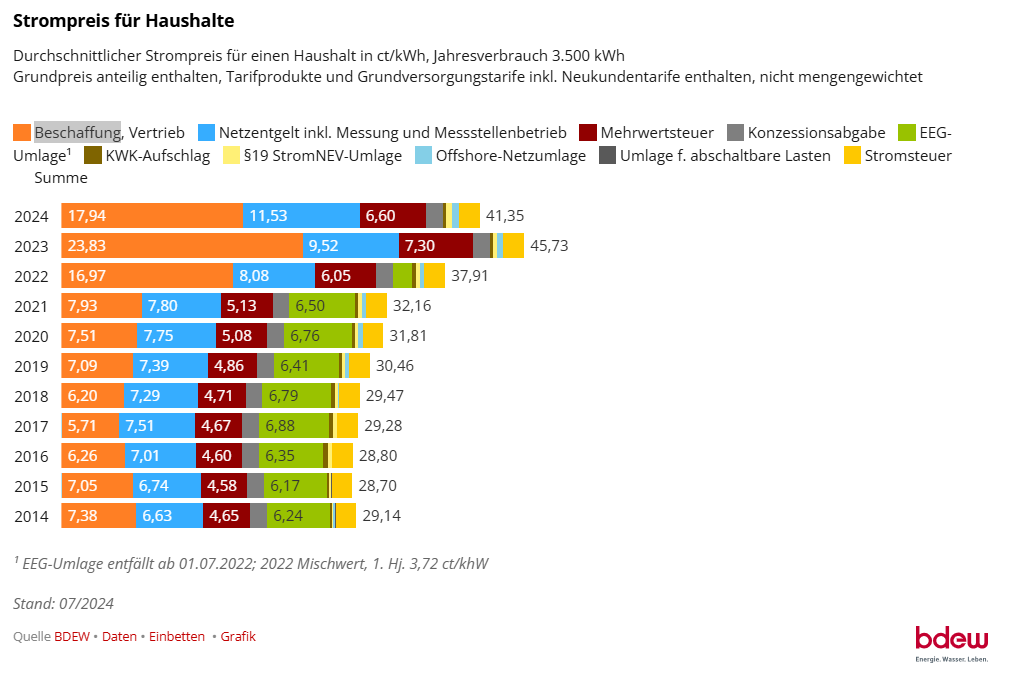

    Year  Beschaffung_Vetrieb  Netzentgelt  Mehrwertsteuer  Summe  Sonstige
0   2024                17.94        11.53            6.60  41.35      5.28
1   2023                23.83         9.52            7.30  45.73      5.08
2   2022                16.97         8.08            6.05  37.91      6.81
3   2021                 7.93         7.80            5.13  32.16     11.30
4   2020                 7.51         7.75            5.08  31.81     11.47
5   2019                 7.09         7.39            4.86  30.46     11.12
6   2018                 7.09         7.29            4.71  29.47     10.38
7   2017                 7.05         7.51            4.67  29.28     10.05
8   2016                 7.05         7.51            4.60  28.80      9.64
9   2015                 7.38         6.63            4.58  28.70     10.11
10  2014                 7.38         6.63            4.56  29.14     10.57


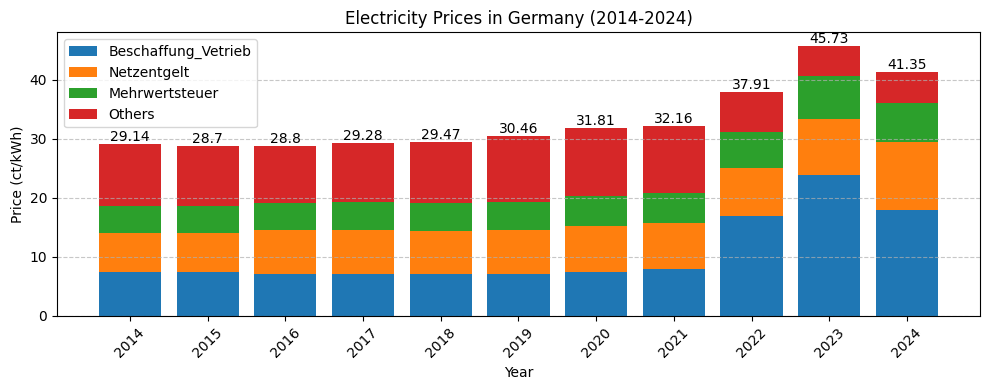

In [104]:
electricity_prices = {
    "Year": [2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014],
    "Beschaffung_Vetrieb": [17.94, 23.83, 16.97, 7.93, 7.51, 7.09, 7.09, 7.05, 7.05, 7.38, 7.38],
    "Netzentgelt": [11.53, 9.52, 8.08, 7.80, 7.75, 7.39, 7.29, 7.51, 7.51, 6.63, 6.63],
    "Mehrwertsteuer": [6.60, 7.30, 6.05, 5.13, 5.08, 4.86, 4.71, 4.67, 4.60, 4.58, 4.56],
    "Summe": [41.35, 45.73, 37.91, 32.16, 31.81, 30.46, 29.47, 29.28, 28.80, 28.70, 29.14]
} #' IN kwH'

# Create DataFrame and add Sonstige column (EEG-Umlage, KWK-Aufschlag, Stromsteuer,...))
electricity_prices_df = pd.DataFrame(electricity_prices)
electricity_prices_df['Sonstige'] = electricity_prices_df['Summe'] - (electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'])
print(electricity_prices_df)

# Plot the data as a stacked bar chart
plt.figure(figsize=(10,4))
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Beschaffung_Vetrieb'], label='Beschaffung_Vetrieb')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Netzentgelt'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'], label='Netzentgelt')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Mehrwertsteuer'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'], label='Mehrwertsteuer')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Sonstige'],bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'], label='Others')
plt.xlabel('Year')
plt.ylabel('Price (ct/kWh)')
for i in range(len(electricity_prices_df)):
    plt.text(electricity_prices_df['Year'][i], electricity_prices_df['Summe'][i] + 0.5, str(electricity_prices_df['Summe'][i]), ha='center') #add values
plt.title('Electricity Prices in Germany (2014-2024)')
plt.xticks(electricity_prices_df['Year'], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Load Household data

- filtered_df = Data of all households in 2019
- filtered_df_test = Data of all households in 2020
  

In [105]:
#Load pickle into dataframe
hh_path = r"local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
start_date = '2019-01-01'
end_date = '2019-12-31'
start_date_test = '2020-01-01'
end_date_test = '2020-12-31'
keyword = 'SFH' # Single Family Households

data_allhouseholds = pd.read_pickle(hh_path)
mask_model = (data_allhouseholds.index >= start_date) & (data_allhouseholds.index < end_date)
mask_test = (data_allhouseholds.index >= start_date_test) & (data_allhouseholds.index < end_date_test)
data_allhouseholds_model = data_allhouseholds.loc[mask_model]
data_allhouseholds_test = data_allhouseholds.loc[mask_test]

# Extract columns that contain the keyword in their name
filtered_df = data_allhouseholds_model.filter(like=keyword)
filtered_df = filtered_df.drop(columns=['SFH34_P_TOT']) # TODO: SHOW WHY Household 34 is shit

filtered_df_test = data_allhouseholds_test.filter(like=keyword)
filtered_df_test = filtered_df_test.drop(columns=['SFH34_P_TOT'])

# turn unit to kWh
filtered_df = filtered_df/1000
filtered_df_test = filtered_df_test/1000

print(filtered_df.head())

#print all column names
print(filtered_df.columns)
print("Number of households: ", len(filtered_df.columns))
print("Number of households: ", len(filtered_df_test.columns))


                           SFH3_P_TOT  SFH4_P_TOT  SFH5_P_TOT  SFH7_P_TOT  \
date                                                                        
2019-01-01 00:00:00+00:00    0.161493    0.378307    0.555783    0.472945   
2019-01-01 01:00:00+00:00    0.201888    0.379044    0.446765    0.303302   
2019-01-01 02:00:00+00:00    0.156627    0.381565    0.301362    0.142379   
2019-01-01 03:00:00+00:00    0.155399    0.427539    0.307746    0.152653   
2019-01-01 04:00:00+00:00    0.112611    0.309020    0.326347    0.208406   

                           SFH9_P_TOT  SFH12_P_TOT  SFH14_P_TOT  SFH16_P_TOT  \
date                                                                           
2019-01-01 00:00:00+00:00    0.276283     0.141515     1.263900     0.138280   
2019-01-01 01:00:00+00:00    0.254865     0.137292     1.251248     0.109699   
2019-01-01 02:00:00+00:00    0.198773     0.133582     1.121481     0.072142   
2019-01-01 03:00:00+00:00    0.241786     0.147410     0.990

#### Show some plots

In [106]:
# Loop through each column in filtered_df and plot the data
"""for column in filtered_df.columns:
    household_data = filtered_df[column]
    
    plt.figure(figsize=(20, 3))
    plt.plot(household_data.index, household_data.values, label=column)
    
    plt.xlabel('Time')
    plt.ylabel('Load [kWh]')
    plt.legend()
    plt.grid(True)
    plt.show()
"""

"for column in filtered_df.columns:\n    household_data = filtered_df[column]\n    \n    plt.figure(figsize=(20, 3))\n    plt.plot(household_data.index, household_data.values, label=column)\n    \n    plt.xlabel('Time')\n    plt.ylabel('Load [kWh]')\n    plt.legend()\n    plt.grid(True)\n    plt.show()\n"

# Models

## 1. Model: Standardlastprofil

Datensatz: SLP 2019 der Stadtwerke Groß-Gerau Versorgung GmbH: https://ggv-energie.de/cms/netz/allgemeine-daten/netzbilanzierung-download-aller-profile.php

- Datensatz enthält Standardlastprofil eines typischen Einfamilien Haushalt (H00)



### Load data and normalize to 3000kwh


Load Data

In [107]:
file_path = r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\data\slp\GGV_SLP_1000_MWh_2019_01.xlsx"
sheet_name = "15Min - SLP 2019" # Single Load Profile 2019

data_15min_slp_2019 = pd.read_excel(file_path, sheet_name=sheet_name)
data_15min_slp_2019.head()

,Messwert-Nr.,Wochentag,Datum,Zeitstempel von,Zeitstempel bis,MP von,MP bis,H00 [kW],H00 [kWh]
0,1,2,2019-01-01,2019-01-01 00:00:00,2019-01-01 00:15:00,00:00,00:15,145.200,36.300
1,2,2,2019-01-01,2019-01-01 00:15:00,2019-01-01 00:30:00,00:15,00:30,140.112,35.028
2,3,2,2019-01-01,2019-01-01 00:30:00,2019-01-01 00:45:00,00:30,00:45,135.720,33.930
3,4,2,2019-01-01,2019-01-01 00:45:00,2019-01-01 01:00:00,00:45,01:00,130.732,32.683
4,5,2,2019-01-01,2019-01-01 01:00:00,2019-01-01 01:15:00,01:00,01:15,127.236,31.809


Data Preparation

In [108]:
data_15min_slp_2019.drop(columns=['Messwert-Nr.','MP von', 'MP bis'], inplace=True)

#Fasse Zeitstempel pro Stunde zusammen und summiere H00 [kW] in neuer df
data_15min_slp_2019['Hour'] = data_15min_slp_2019['Zeitstempel von'].dt.floor('h')
data_slp_hourly_2019 = data_15min_slp_2019.groupby('Hour').agg({'H00 [kW]': 'sum'}).reset_index()
data_slp_hourly_2019['H00 [kWh]'] = data_slp_hourly_2019['H00 [kW]'] / 4 
#add 'Wochentag'
data_slp_hourly_2019['Weekday'] = data_slp_hourly_2019['Hour'].dt.day_name()

#Normalizing the values to a "average household" with 3000 kWh  
data_slp_hourly_2019['H00_Norm [kWh]'] = data_slp_hourly_2019['H00 [kWh]'] /data_slp_hourly_2019['H00 [kWh]'].sum()*3000

data_slp_hourly_2019.head()

,Hour,H00 [kW],H00 [kWh],Weekday,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0.289656


## 2. Model Implementation. Assumption: Average Household 

1. Normalization of data ( so that every household has the same annual energy consumption):
- creating a new list with Household and annual consumption (adding up all the values based on this one year)
- Normalizing the values to a "average household" with 3000 kWh  

Output: _normalized_data_

2. Buidling average load profile of all households per hour 

3. Finding Base Load



In [109]:
# 1. Normalization

# add all columns for each household and save it in a new table "householdname" AND "Householdname_annual_total"
data_annual_total_loads = pd.DataFrame()
for i in filtered_df.columns:
    data_annual_total_loads.loc['Annual Total', i] = filtered_df[i].sum()
#print(data_annual_total_loads)

# Normalization auf 3000kwH Houshehold
normalized_data = filtered_df.copy()
for i in filtered_df.columns:
    normalized_data[i] = filtered_df[i] / data_annual_total_loads.loc['Annual Total', i] * 3000
print("Normalized Test 2019",normalized_data)

normalized_data_test = filtered_df_test.copy()
for i in filtered_df_test.columns:
    normalized_data_test[i] = filtered_df_test[i] / data_annual_total_loads.loc['Annual Total', i] * 3000
print("Normalized Test 2020:", normalized_data_test)


Normalized Test 2019                            SFH3_P_TOT  SFH4_P_TOT  SFH5_P_TOT  SFH7_P_TOT  \
date                                                                        
2019-01-01 00:00:00+00:00    0.238340    0.367928    0.548614    0.463687   
2019-01-01 01:00:00+00:00    0.297956    0.368645    0.441002    0.297365   
2019-01-01 02:00:00+00:00    0.231157    0.371096    0.297475    0.139592   
2019-01-01 03:00:00+00:00    0.229346    0.415809    0.303776    0.149664   
2019-01-01 04:00:00+00:00    0.166197    0.300542    0.322137    0.204326   
...                               ...         ...         ...         ...   
2019-12-30 19:00:00+00:00    0.386890    0.432991    0.426607    0.525248   
2019-12-30 20:00:00+00:00    0.398294    0.446505    0.479816    0.403152   
2019-12-30 21:00:00+00:00    0.282578    0.405866    0.446371    0.198264   
2019-12-30 22:00:00+00:00    0.177112    0.216589    0.441483    0.174686   
2019-12-30 23:00:00+00:00    0.272085    0.217238    0.

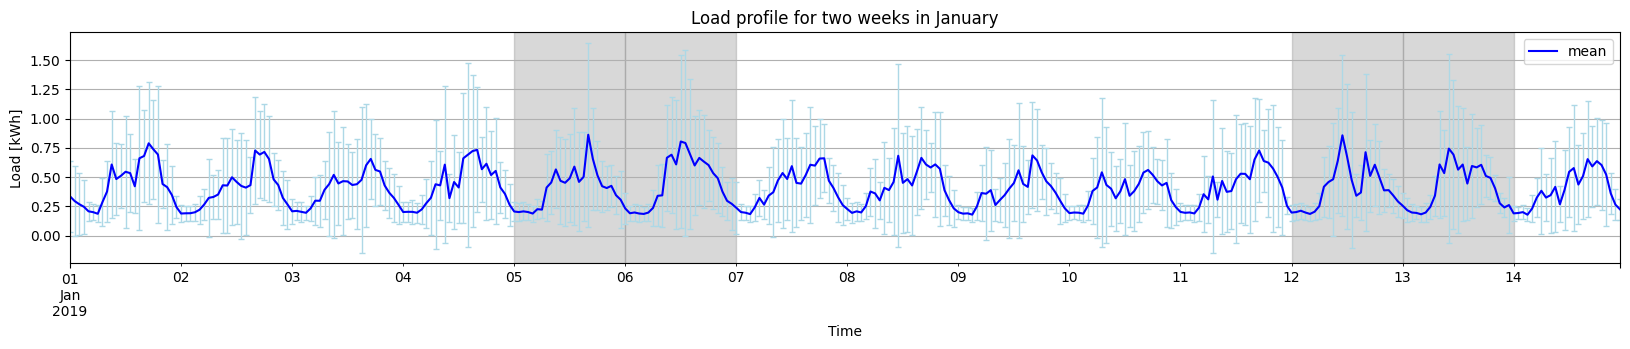

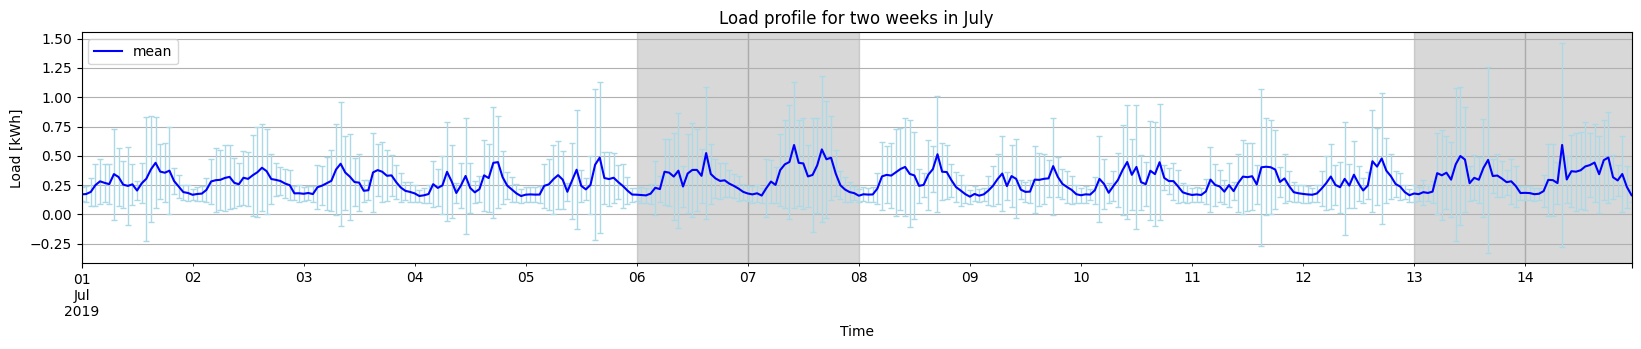

In [110]:
# 2. Buidling average load profile of all households per hour 2019

# Calculate the mean of all households for each hour
average_hh_load_profile_2019 = normalized_data.mean(axis=1)
average_hh_load_profile_2019 = pd.DataFrame(average_hh_load_profile_2019)

#add standard deviation to the average load profile
std_dev = normalized_data.std(axis=1)
average_hh_load_profile_2019 = pd.concat([average_hh_load_profile_2019, std_dev], axis=1)
average_hh_load_profile_2019.columns = ['mean', 'std_dev']


#add Weekend/Work-Day information to the average load profile
average_hh_load_profile_2019['Weekday'] = average_hh_load_profile_2019.index.weekday 
average_hh_load_profile_2019['Weekday'] = average_hh_load_profile_2019['Weekday'].apply(lambda x: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'][x])
average_hh_load_profile_2019['DayType'] = average_hh_load_profile_2019['Weekday'].apply(lambda x: 'Workday' if x in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'] else 'Weekend')
average_hh_load_profile_2019['Hour'] = average_hh_load_profile_2019.index.hour

# Plot for two weeks in January and mark grey if day is weekend
fig, ax = plt.subplots(figsize=(20, 3))
average_hh_load_profile_2019['2019-01-01':'2019-01-14'].plot(y='mean', yerr='std_dev', ax=ax, color='blue', ecolor='lightblue', elinewidth=1, capsize=2)

# Mark weekends in grey
for day in pd.date_range(start='2019-01-01', end='2019-01-14'):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)

plt.title('Load profile for two weeks in January')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.show()

# Plot for two weeks in July and mark grey if day is weekend
fig, ax = plt.subplots(figsize=(20, 3))
average_hh_load_profile_2019['2019-07-01':'2019-07-14'].plot(y='mean', yerr='std_dev', ax=ax, color='blue', ecolor='lightblue', elinewidth=1, capsize=2)

# Mark weekends in grey
for day in pd.date_range(start='2019-07-01', end='2019-07-14'):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)

plt.title('Load profile for two weeks in July')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.show()





### Load information for each Season on average of all households
- base load
- peak load

In [111]:
#Spring
spring_start = '2019-03-01'	
spring_end = '2019-05-31'
#Summer
summer_start = '2019-06-01'
summer_end = '2019-08-31'
#Autumn
autumn_start = '2019-09-01'
autumn_end = '2019-11-30'
#Winter
winter_start1 = '2019-01-01'
winter_end1 = '2019-02-28'
winter_start2 = '2019-12-01'	
winter_end2 = '2019-12-31'

base_load_spring = average_hh_load_profile_2019[spring_start:spring_end]['mean'].min()
peak_load_spring = average_hh_load_profile_2019[spring_start:spring_end]['mean'].max()

print('Spring base load:', base_load_spring)
print('Spring peak load:', peak_load_spring)

base_load_summer = average_hh_load_profile_2019[summer_start:summer_end]['mean'].min()
peak_load_summer = average_hh_load_profile_2019[summer_start:summer_end]['mean'].max()
print('Summer base load:', base_load_summer)
print('Summer peak load:', peak_load_summer)

base_load_autumn = average_hh_load_profile_2019[autumn_start:autumn_end]['mean'].min()
peak_load_autumn = average_hh_load_profile_2019[autumn_start:autumn_end]['mean'].max()
print('Autumn base load:', base_load_autumn)
print('Autumn peak load:', peak_load_autumn)


base_load_winter = (average_hh_load_profile_2019[winter_start1:winter_end1]['mean'].min() + average_hh_load_profile_2019[winter_start2:winter_end2]['mean'].min())*0.5
peak_load_winter = (average_hh_load_profile_2019[winter_start1:winter_end1]['mean'].max() + average_hh_load_profile_2019[winter_start2:winter_end2]['mean'].max())*0.5
print('Winter base load:', base_load_winter)
print('Winter peak load:', peak_load_winter)




Spring base load: 0.16081517227420825
Spring peak load: 0.8520695569373269
Summer base load: 0.15219640651008726
Summer peak load: 0.661503135290726
Autumn base load: 0.15414054077505757
Autumn peak load: 0.8805133488119036
Winter base load: 0.1688485369208198
Winter peak load: 0.8618687872262718


                           SFH3_P_TOT  weekday
date                                          
2019-01-01 00:00:00+00:00    0.238340  Tuesday
2019-01-01 01:00:00+00:00    0.297956  Tuesday
2019-01-01 02:00:00+00:00    0.231157  Tuesday
2019-01-01 03:00:00+00:00    0.229346  Tuesday
2019-01-01 04:00:00+00:00    0.166197  Tuesday
                           SFH3_P_TOT  weekday  hour
date                                                
2019-01-01 00:00:00+00:00    0.238340  Tuesday     0
2019-01-01 01:00:00+00:00    0.297956  Tuesday     1
2019-01-01 02:00:00+00:00    0.231157  Tuesday     2
2019-01-01 03:00:00+00:00    0.229346  Tuesday     3
2019-01-01 04:00:00+00:00    0.166197  Tuesday     4
                SFH3_P_TOT
weekday   hour            
Friday    0       0.198318
          1       0.229456
          2       0.230481
          3       0.237162
          4       0.239451
...                    ...
Wednesday 19      0.303254
          20      0.267048
          21      0.222841
   

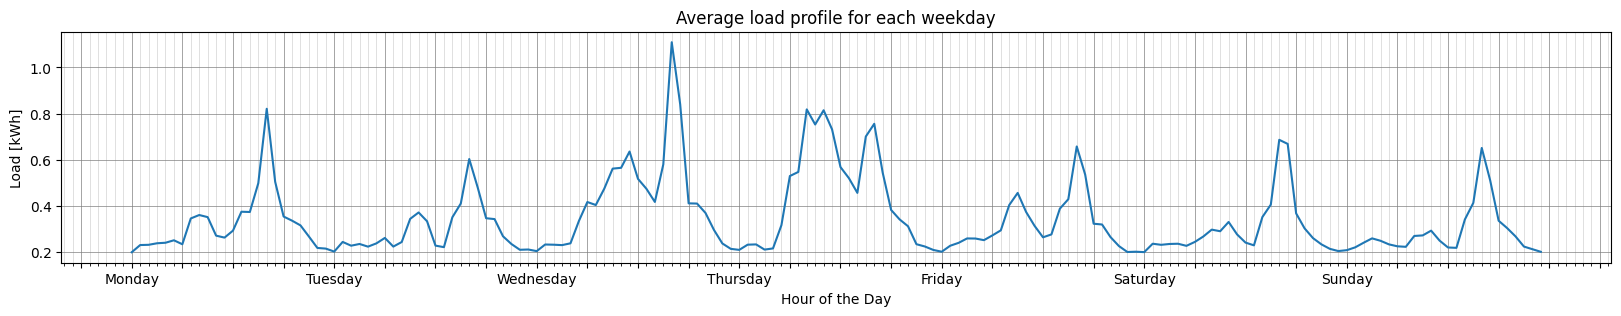

In [112]:
# Testing household weekly average load profile for one household
example_household_data = normalized_data['SFH3_P_TOT']  # Replace 'SFH3_P_TOT' with the correct column name after identifying it
#print(example_household_data.head())

# Add column with the specific weekday
example_household_data = example_household_data.to_frame()
example_household_data['weekday'] = example_household_data.index.weekday
example_household_data['weekday'] = example_household_data['weekday'].apply(lambda x: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'][x])
print(example_household_data.head())

# Add column with specific hour of the day
example_household_data['hour'] = example_household_data.index.hour
print(example_household_data.head())

# Calculate the mean load profile for each weekday and hour of the day
example_household_data_mean = example_household_data.groupby(['weekday', 'hour']).mean()
print(example_household_data_mean)


# Add to example_household_data_mean a column containing a specific date for each weekday and hour combination
example_household_data_mean['datetime'] = [pd.Timestamp(f'2023-01-0{(i % 7) + 1} {hour}:00:00') for i, (weekday, hour) in enumerate(example_household_data_mean.index)]
example_household_data_mean.set_index('datetime', inplace=True)
print(example_household_data_mean)


# Plot average week
fig, ax = plt.subplots(figsize=(20, 3))
example_household_data_mean.unstack(level=0).plot(ax=ax)
plt.title('Average load profile for each weekday')
plt.xlabel('Hour of the Day')
plt.ylabel('Load [kWh]')
ax.set_xticks(range(0, 24 * 7, 24))
ax.set_xticklabels(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.grid(True)

# Add a grid for the hours in light grey
ax.xaxis.set_major_locator(plt.MultipleLocator(1))
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax.grid(which='both', color='lightgrey', linestyle='-', linewidth=0.5)

# Make grid lines bold every 6 hours
ax.xaxis.set_major_locator(plt.MultipleLocator(6))
ax.grid(which='major', color='grey', linestyle='-', linewidth=0.5)

plt.show()



## 2. Model Erweiterung Customer Data
- data_customer
- data_customer_load_profile_two_random_weeks
- customer_annual_electricity_consumption



#### Which infoirmation can be aggregated from this dataset? 
customer_annual_electricity_consumption 
- normalization value for model information 

data_customer_load_profile_two_random_weeks
- which season are we in?
- calculate average weekday behaviour and compare it with average weekday behavior of average household
- use this together with seasonal change for calculating yearly load prediction

-------------Information-------------
Information about the selected household SFH9_P_TOT:
Total annual consumption: 4661.779069749514 kWh
Selected two weeks: 2019-11-24 00:00:00+00:00 to 2019-12-08 00:00:00+00:00
The season for the selected two weeks is: Autumn
Base load of the customer household: 0.08330285381467763 kWh
Peak load of the customer household: 1.8159662570996817 kWh
-------------Plots-------------


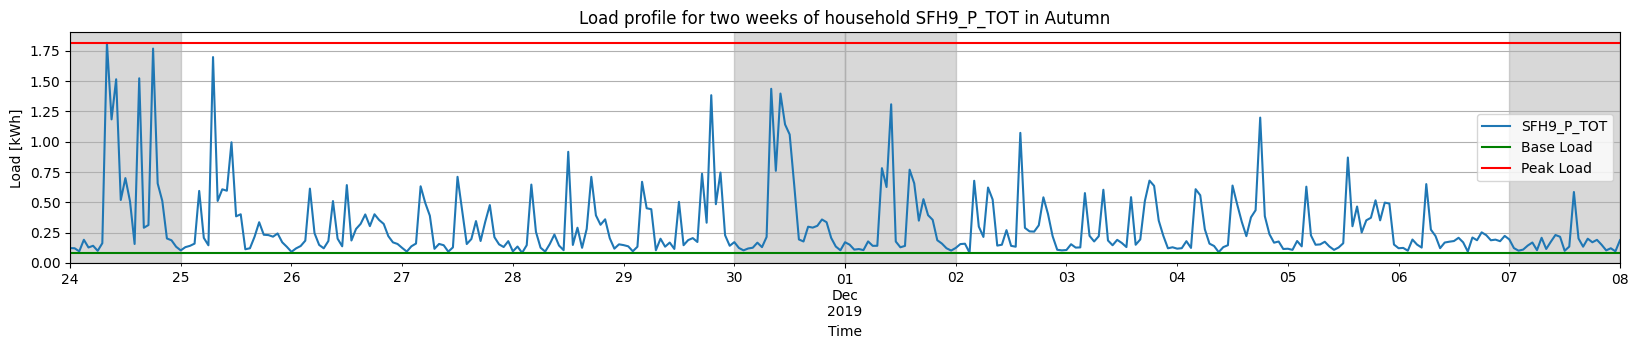

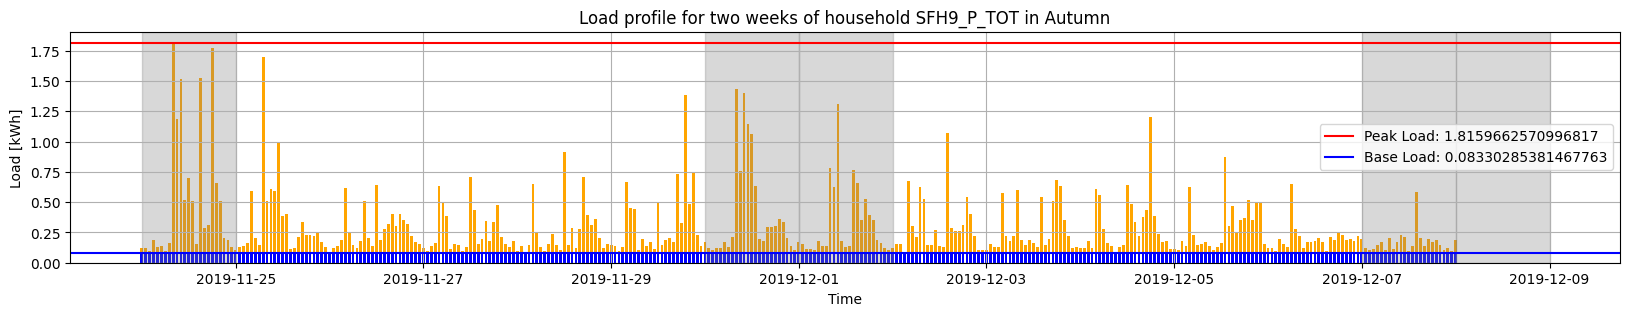

In [113]:
# Random Household Selection
# We take a random household as our customer household, the data here is already normalized. In a real dataset this needs to be done first! #TODO

random_household = random.choice(normalized_data.columns)
random_household = 'SFH9_P_TOT'  # Replace 'SFH9_P_TOT' with the column name after identifying it


# Extract the data for the selected random household
customer_household_data = normalized_data[random_household]
customer_household_data_test = normalized_data_test[random_household]

# randomly take two weeks of the household data
random_start_date = random.choice(pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date) - pd.Timedelta(days=14), tz='UTC'))
random_end_date = random_start_date + pd.Timedelta(days=14)


#Filter data for the two weeks
customer_household_data = customer_household_data[random_start_date:random_end_date]
#Which season are we in?
def get_season(date):
    if date.month in [12, 1, 2]:
        return 'Winter'
    elif date.month in [3, 4, 5]:
        return 'Spring'
    elif date.month in [6, 7, 8]:
        return 'Summer'
    elif date.month in [9, 10, 11]:
        return 'Autumn'
season_customer_data = get_season(random_start_date)


#CAlculate base load over this two weeks. Base load is defined as die Leistung, die kontinuierlich benötigt wird und somit den minimalen Energiebedarf eeines HH.
#In einem Einfamilienhaus liegt die durchschnittliche Grundlast bei etwa 300 bis 400 Watt. Dieser meist vermeidbare Verbrauch wird in privaten Haushalten hauptsächlich durch das Nicht-Ausschalten oder das nicht vollständige Ausschalten von elektronischen Geräten verursacht.

base_load_customer = customer_household_data[customer_household_data.index].min()

# Calculate medium load
#medium_load_customer = customer_household_data[customer_household_data.index].median()
#print('Medium load of the customer household:', medium_load_customer)

# Calculate peak load
peak_load_customer = customer_household_data[customer_household_data.index].max()


#Print information about the selected household
print('-------------Information-------------')
print(f"Information about the selected household {random_household}:")
print(f"Total annual consumption: {data_annual_total_loads.loc['Annual Total', random_household]} kWh")
print(f"Selected two weeks: {random_start_date} to {random_end_date}")
print(f"The season for the selected two weeks is: {season_customer_data}")
print('Base load of the customer household:', base_load_customer, 'kWh')
print('Peak load of the customer household:', peak_load_customer, 'kWh')
print('-------------Plots-------------')


#Plot load profile of the customer household with colors for base, medium and peak load.
fig, ax = plt.subplots(figsize=(20, 3))
customer_household_data.plot(ax=ax)
for day in pd.date_range(start=random_start_date, end=random_end_date):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)
plt.title(f'Load profile for two weeks of household {random_household} in {season_customer_data}')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.axhline(y=base_load_customer, color='green', linestyle='-', label='Base Load')
#plt.axhline(y=medium_load_customer, color='yellow', linestyle='-', label='Medium Load')
plt.axhline(y=peak_load_customer, color='red', linestyle='-', label='Peak Load')
plt.legend()
plt.show()
# Plot load profile of the customer household with colors for base, medium, and peak load as a bar graph
fig, ax = plt.subplots(figsize=(20, 3))

# Define colors for different load levels
colors = ['blue', 'orange', 'red']

# Create a bar plot with different colors for base, medium, and peak load
for i in range(len(customer_household_data)):
    load = customer_household_data.iloc[i]
    if load <= base_load_customer:
        ax.bar(customer_household_data.index[i], load, color=colors[0], width=0.03)
    elif load <= peak_load_customer:
        ax.bar(customer_household_data.index[i], base_load_customer, color=colors[0], width=0.03)
        ax.bar(customer_household_data.index[i], load - base_load_customer, bottom=base_load_customer, color=colors[1], width=0.03)
plt.axhline(y=peak_load_customer, color='red', linestyle='-', label='Peak Load: ' + str(peak_load_customer))  
plt.axhline(y=base_load_customer, color='blue', linestyle='-', label='Base Load: ' + str(base_load_customer))
#plt.axhline(y=medium_load_customer, color='yellow', linestyle='-', label='Medium Load: ' + str(medium_load_customer))

# Mark weekends in grey
for day in pd.date_range(start=random_start_date, end=random_end_date):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)

plt.title(f'Load profile for two weeks of household {random_household} in {season_customer_data}')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.legend()
plt.show()


#Average weekday of customer household two week data



In [114]:
# add column with the specific weekday and hour to the customer_household_data
customer_household_data = customer_household_data.to_frame(name='Load')
customer_household_data['Weekday'] = customer_household_data.index.weekday
customer_household_data['Weekday'] = customer_household_data['Weekday'].apply(
    lambda x: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'][x]
)
customer_household_data['DayType'] = customer_household_data['Weekday'].apply(
    lambda x: 'Workday' if x in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'] else 'Weekend'
)
customer_household_data['Hour'] = customer_household_data.index.hour



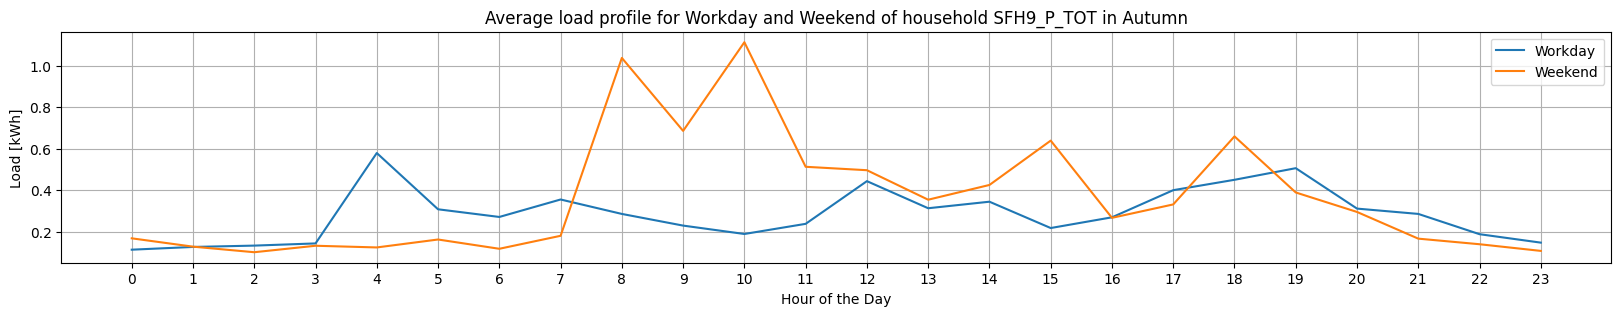

In [115]:
# Calculate the mean load profile for Workday and Weekend per hour for the customer household
customer_household_average_workday = customer_household_data[customer_household_data['DayType'] == 'Workday'].groupby('Hour')['Load'].mean()
customer_household_average_weekend = customer_household_data[customer_household_data['DayType'] == 'Weekend'].groupby('Hour')['Load'].mean()

# Plot average load profile for Workday and Weekend
fig, ax = plt.subplots(figsize=(20, 3))
customer_household_average_workday.plot(ax=ax, label='Workday')
customer_household_average_weekend.plot(ax=ax, label='Weekend')
plt.title(f'Average load profile for Workday and Weekend of household {random_household} in {season_customer_data}')
plt.xlabel('Hour of the Day')
plt.xticks(range(0, 24, 1))
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.legend()
plt.show()

### Calculation of customer load profile for the next year

Weighted combination of both dataset
- customer data: granular short-term data set
- annual load profile of the average households (average_load_profile) for long-term seasonality and daily patterns 

Creates a weighted sum of the two datasets: 
- Assigning higher weight to the two-week load profile for capturing recent trends. 
- Using the average household load profile for long-term corrections.



In [ ]:
# Define the target full-year date range
start_date_test = '2020-01-01'
end_date_test = '2020-12-31'
date_range = pd.date_range(start=start_date_test, end=end_date_test, freq='H', tz='UTC') # hourly data

# Separate two-week customer data into workday and weekend profiles and calculate the average load per hour
workday_load = customer_household_data[customer_household_data['DayType'] == 'Workday']['Load']
weekend_load = customer_household_data[customer_household_data['DayType'] == 'Weekend']['Load']
average_workday_load = workday_load.groupby(workday_load.index.hour).mean()
average_weekend_load = weekend_load.groupby(weekend_load.index.hour).mean()

# Create a DataFrame with the full-year date range as index by expanidng the two week data
predicted_household_data = pd.DataFrame(index=date_range)
predicted_household_data['Weekday'] = predicted_household_data.index.weekday
predicted_household_data['Hour'] = predicted_household_data.index.hour
predicted_household_data['Season'] = predicted_household_data.index.map(get_season)
predicted_household_data['DayType'] = predicted_household_data['Weekday'].apply(
    lambda x: 'Workday' if x in [0, 1, 2, 3, 4] else 'Weekend'
)
predicted_household_data = predicted_household_data[:-1] #delete 2020-12-31 00:00:00+00:00

# Calculate the load based on the customer's average workday and weekend load profiles
predicted_household_data['Load_basedOnCustomer'] = predicted_household_data.apply(lambda row: average_workday_load[row['Hour']] if row['DayType'] == 'Workday' else average_weekend_load[row['Hour']], axis=1)

print("---Predicted Household Data 2020---")  
print(predicted_household_data)

print("---average_hh_load_profile_2019---")
print(average_hh_load_profile_2019)



---Predicted Household Data 2020---
                           Weekday  Hour  Season  DayType  \
2020-01-01 00:00:00+00:00        2     0  Winter  Workday   
2020-01-01 01:00:00+00:00        2     1  Winter  Workday   
2020-01-01 02:00:00+00:00        2     2  Winter  Workday   
2020-01-01 03:00:00+00:00        2     3  Winter  Workday   
2020-01-01 04:00:00+00:00        2     4  Winter  Workday   
...                            ...   ...     ...      ...   
2020-12-30 19:00:00+00:00        2    19  Winter  Workday   
2020-12-30 20:00:00+00:00        2    20  Winter  Workday   
2020-12-30 21:00:00+00:00        2    21  Winter  Workday   
2020-12-30 22:00:00+00:00        2    22  Winter  Workday   
2020-12-30 23:00:00+00:00        2    23  Winter  Workday   

                           Load_basedOnCustomer  
2020-01-01 00:00:00+00:00              0.114639  
2020-01-01 01:00:00+00:00              0.127813  
2020-01-01 02:00:00+00:00              0.134267  
2020-01-01 03:00:00+00:00      

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_13988\1732769659.py:4: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_range = pd.date_range(start=start_date_test, end=end_date_test, freq='H', tz='UTC') # hourly data


In [134]:
# Merge with average househol
# d load profile and predict the load using weighted averages # TODO das ist hier falsch, da merge nicht mehr mit Jahren funktioneirt. 
customer_household_data_prediction = predicted_household_data.merge(average_hh_load_profile_2019, left_index=True, right_index=True, how='left')

weight_offseason_customer = 0.5
weight_offseason_averageHH = 0.5

weight_customer = 0.7
weight_averageHH = 0.3

# Predict the load based on the weighted average of the customer's data and the average household data. Depends also on the seasonality of the dataset
customer_household_data_prediction['Load_prediction'] = 0
customer_household_data_prediction['Load_prediction'] = customer_household_data_prediction.apply(
    lambda row: (weight_customer * row['Load_basedOnCustomer'] + weight_averageHH * row['mean']) 
    if row['Season'] == season_customer_data 
    else (weight_offseason_customer * row['Load_basedOnCustomer'] + weight_offseason_averageHH * row['mean']), 
    axis=1
)
customer_household_data_prediction.drop(columns=['Weekday_x', 'Hour_x','std_dev', 'Weekday_y', 'Hour_y'], inplace=True)

#NOrmalize predicted data to 3000kWh
sum_predicted_load = customer_household_data_prediction['Load_prediction'].sum()
customer_household_data_prediction['Load_prediction'] = customer_household_data_prediction['Load_prediction'] / sum_predicted_load * 3000




print("---Customer Household Data Prediction---")
print(customer_household_data_prediction)

---Customer Household Data Prediction---
                           Season DayType_x  Load_basedOnCustomer  mean  \
2020-01-01 00:00:00+00:00  Winter   Workday              0.114639   NaN   
2020-01-01 01:00:00+00:00  Winter   Workday              0.127813   NaN   
2020-01-01 02:00:00+00:00  Winter   Workday              0.134267   NaN   
2020-01-01 03:00:00+00:00  Winter   Workday              0.144766   NaN   
2020-01-01 04:00:00+00:00  Winter   Workday              0.579752   NaN   
...                           ...       ...                   ...   ...   
2020-12-30 19:00:00+00:00  Winter   Workday              0.506831   NaN   
2020-12-30 20:00:00+00:00  Winter   Workday              0.312317   NaN   
2020-12-30 21:00:00+00:00  Winter   Workday              0.286751   NaN   
2020-12-30 22:00:00+00:00  Winter   Workday              0.189176   NaN   
2020-12-30 23:00:00+00:00  Winter   Workday              0.148542   NaN   

                          DayType_y  Load_prediction  
202

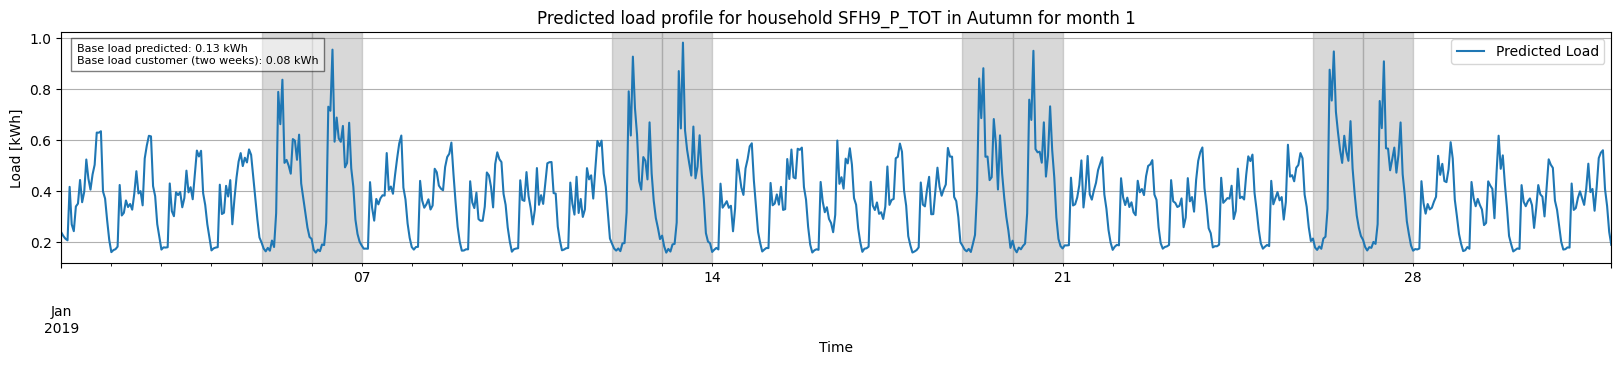

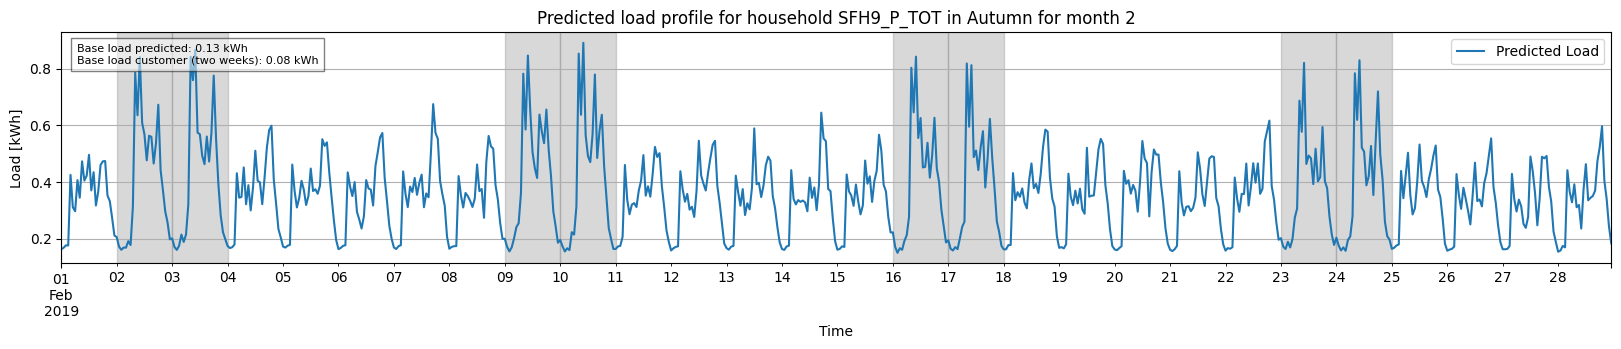

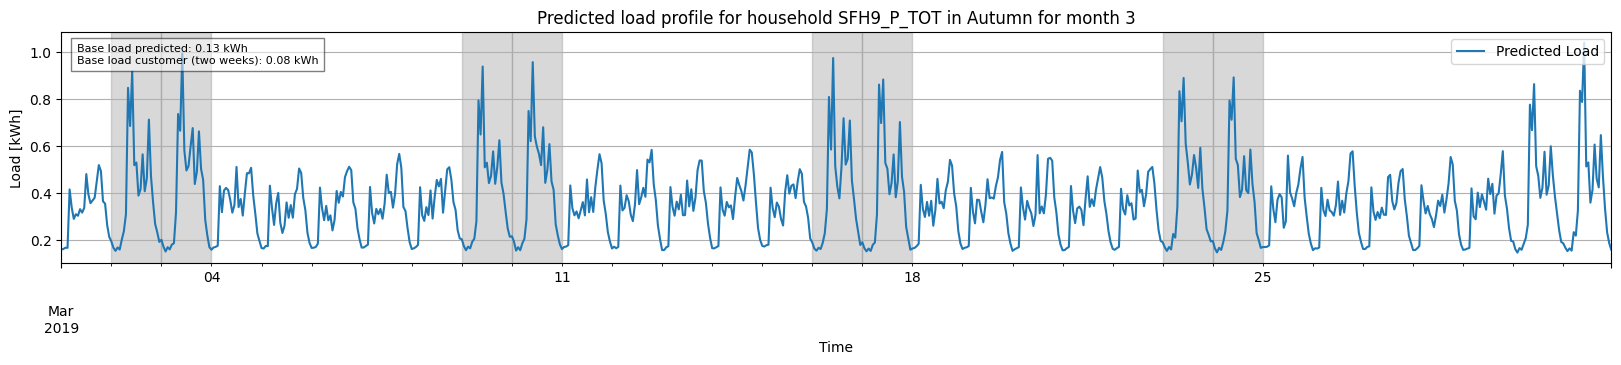

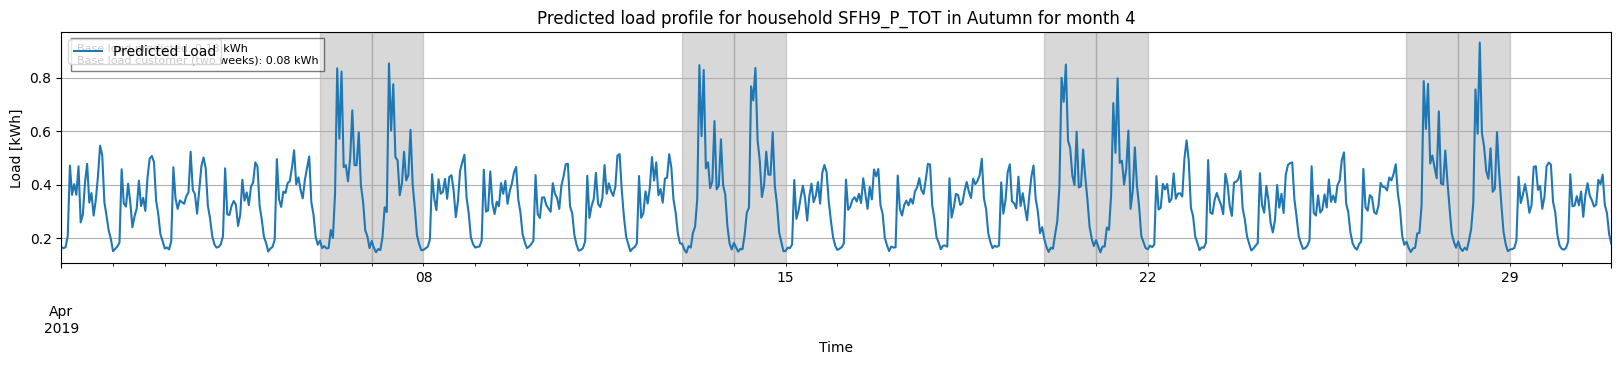

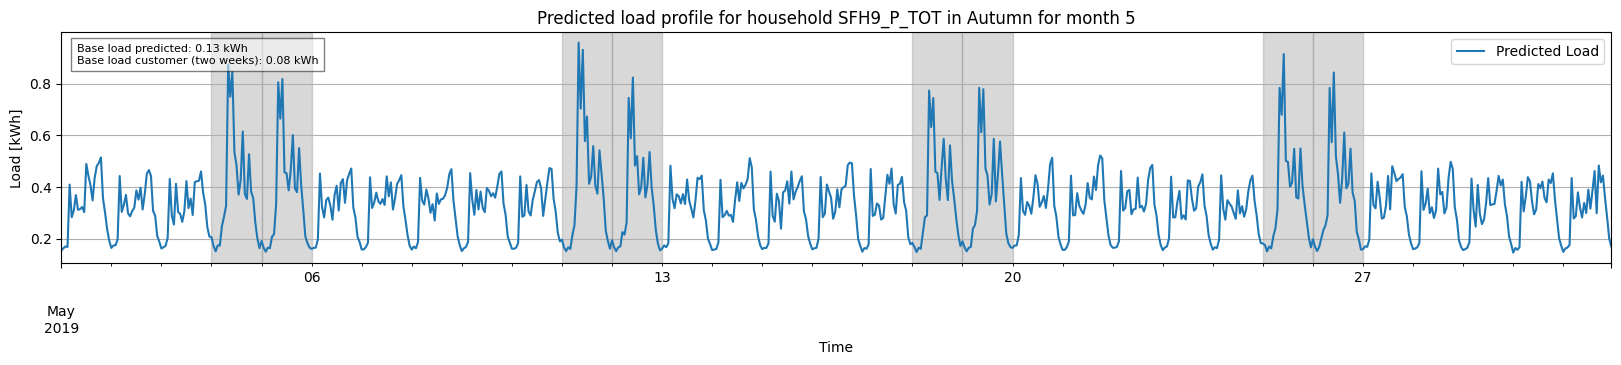

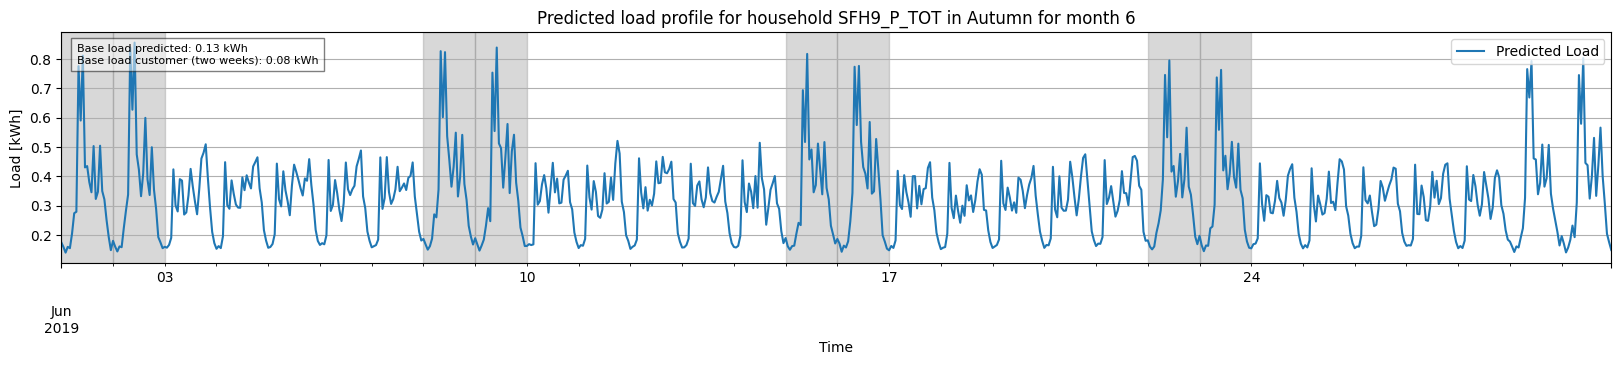

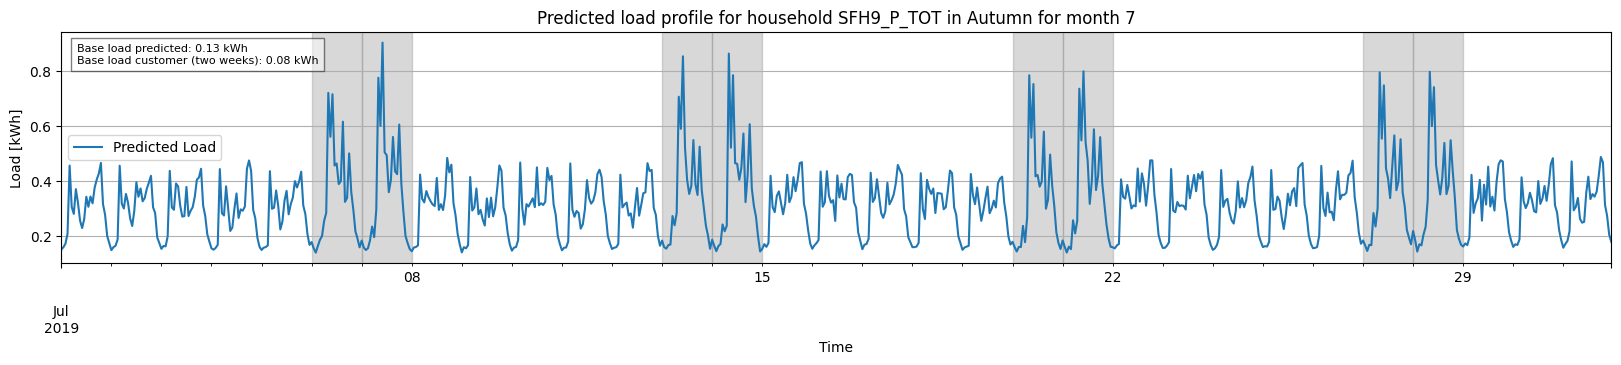

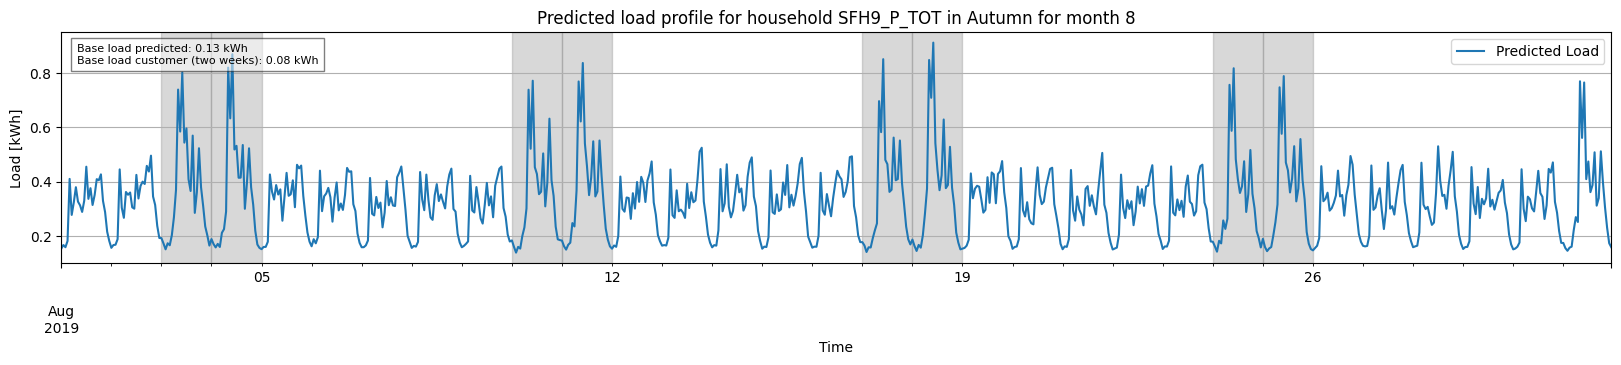

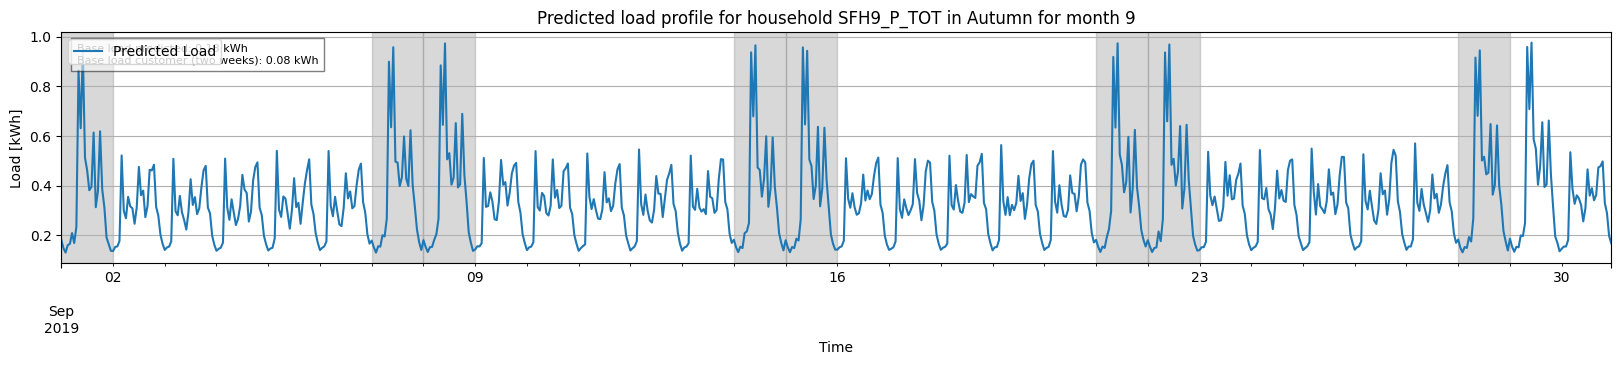

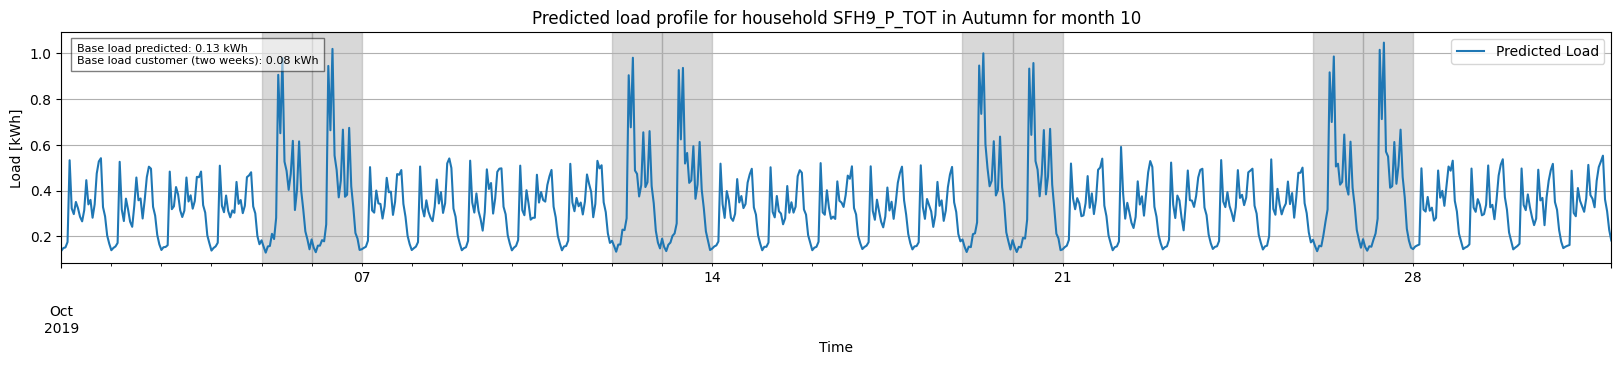

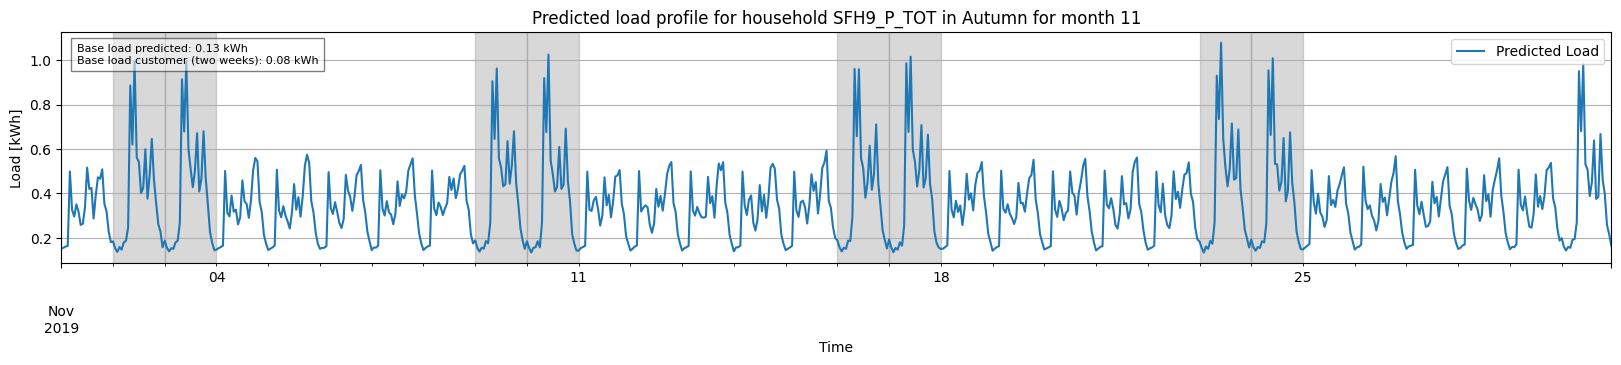

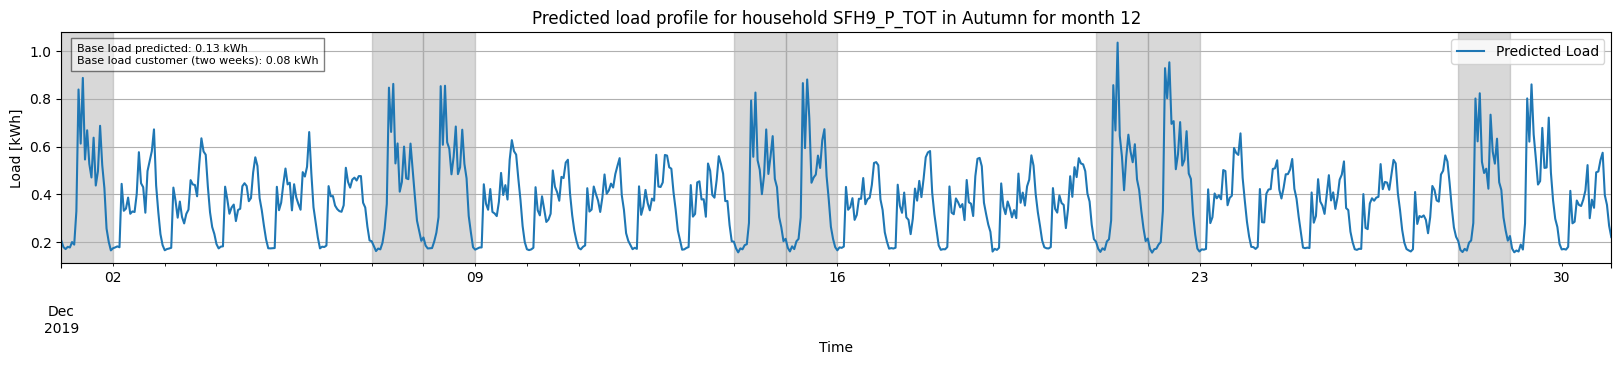

In [118]:
# Plot the predicted load profile for the customer household separately for each month
for month in range(1, 13):
    fig, ax = plt.subplots(figsize=(20, 3))
    monthly_data = customer_household_data_prediction[customer_household_data_prediction.index.strftime('%Y-%m') == f'2019-{month:02}']
    monthly_data['Load_prediction'].plot(ax=ax, label='Predicted Load')
    plt.title(f'Predicted load profile for household {random_household} in {season_customer_data} for month {month}')
    plt.xlabel('Time')
    plt.ylabel('Load [kWh]')
    # Display base load information in the top left corner of the plot
    plt.text(0.01, 0.95, f'Base load predicted: {customer_household_data_prediction["Load_prediction"].min():.2f} kWh\nBase load customer (two weeks): {base_load_customer:.2f} kWh', 
             horizontalalignment='left', verticalalignment='top', transform=ax.transAxes, fontsize=8, bbox=dict(facecolor='white', alpha=0.5))
    #weekends in grey
    for day in pd.date_range(start=f'2019-{month:02}-01', end=f'2019-{month:02}-28'):
        if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
            ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)
    plt.grid(True)
    plt.legend()
    plt.show()


### Comparison with Average Household of all Households

Therefore we compare
- Annual consumption (here not needed, as we already normalized all the housheolds to a consumption of 3000kWh)

With the average household profile in the specific season (Spring, Summer, Autumn or Winter)
- Base Load 
- Peak Load 
- Hourly Difference




In [119]:
average_hh_load_profile_2019

,mean,std_dev,Weekday,DayType,Hour
date,,,,,
2019-01-01 00:00:00+00:00,0.335430,0.304543,Tuesday,Workday,0
2019-01-01 01:00:00+00:00,0.295135,0.297091,Tuesday,Workday,1
2019-01-01 02:00:00+00:00,0.268530,0.263804,Tuesday,Workday,2
2019-01-01 03:00:00+00:00,0.246350,0.232963,Tuesday,Workday,3
2019-01-01 04:00:00+00:00,0.207603,0.081456,Tuesday,Workday,4
...,...,...,...,...,...
2019-12-30 19:00:00+00:00,0.576119,0.570221,Monday,Workday,19
2019-12-30 20:00:00+00:00,0.435573,0.277190,Monday,Workday,20
2019-12-30 21:00:00+00:00,0.384651,0.219284,Monday,Workday,21


In [120]:
print('-------------Summary-------------')
print(f"Information about the selected cutsomer household {random_household}:")
print(" ")
print("A) Total annual consumption")
print(f"Total annual consumption customer household:{filtered_df[random_household].sum()} kWh")
print(f"After normalization costumer houshold: {normalized_data[random_household].sum()} kWh")
print(f"Total annual consumption average household: {average_hh_load_profile_2019["mean"].sum()} kWh")

print(" ")
print("B) Seasonal comparison")
print(f"Randomly selected two weeks of customer measures: {random_start_date} to {random_end_date}")
print(f"Season: {season_customer_data}")
print(f"Base load of the customer household: {base_load_customer} kWh")
print(f"Peak load of the customer household: {peak_load_customer} kWh")
if season_customer_data == 'Winter':
    print(f"Base load of the average household: {base_load_winter} kWh")
    print(f"Peak load of the average household: {peak_load_winter} kWh")
elif season_customer_data == 'Summer':
    print(f"Base load of the average household: {base_load_summer} kWh")
    print(f"Peak load of the average household: {peak_load_summer} kWh")
elif season_customer_data == 'Autumn':
    print(f"Base load of the average household: {base_load_autumn} kWh")
    print(f"Peak load of the average household: {peak_load_autumn} kWh")
elif season_customer_data == 'Spring':
    print(f"Base load of the average household: {base_load_spring} kWh")
    print(f"Peak load of the average household: {peak_load_spring} kWh")




print(" ")
print("C) Load profile comparison with Plot")

print(customer_household_data)
print(average_hh_load_profile_2019)



-------------Summary-------------
Information about the selected cutsomer household SFH9_P_TOT:
 
A) Total annual consumption
Total annual consumption customer household:4661.779069749514 kWh
After normalization costumer houshold: 3000.0000000000005 kWh
Total annual consumption average household: 3000.0 kWh
 
B) Seasonal comparison
Randomly selected two weeks of customer measures: 2019-11-24 00:00:00+00:00 to 2019-12-08 00:00:00+00:00
Season: Autumn
Base load of the customer household: 0.08330285381467763 kWh
Peak load of the customer household: 1.8159662570996817 kWh
Base load of the average household: 0.15414054077505757 kWh
Peak load of the average household: 0.8805133488119036 kWh
 
C) Load profile comparison with Plot
                               Load   Weekday  DayType  Hour
date                                                        
2019-11-24 00:00:00+00:00  0.122310    Sunday  Weekend     0
2019-11-24 01:00:00+00:00  0.120673    Sunday  Weekend     1
2019-11-24 02:00:00+00:

# Testing
Compare the real load profile with the predicted load profile and calculate the costs for the customer.

Parameters:
- df_real_profile: DataFrame, the DataFrame containing the real load profile of the customer on an hourly basis.
- df_predicted_profile: DataFrame, the DataFrame containing the predicted load profile of the customer on an hourly basis.
- df_dynamic_price: DataFrame, the DataFrame containing the dynamic price of electricity on an hourly basis.

Return
- float, the costs for the customer based on the dynamic price of electricity.
- bool, True if the predicted load profile is accurate, False otherwise.

TODO: Write the code

- Compare the real load profile with the predicted load profile on an hourly basis. Return MAPE
- Calculate the mean absolute percentage error (MAPE) for the predicted load profile
- Calculate the costs for the customer based on the dynamic price of electricity. The costs are the sum of the product of the predicted load profile and the dynamic price of electricity on an hourly basis.

Mean Absolute Percentage Error (MAPE): 72.14%


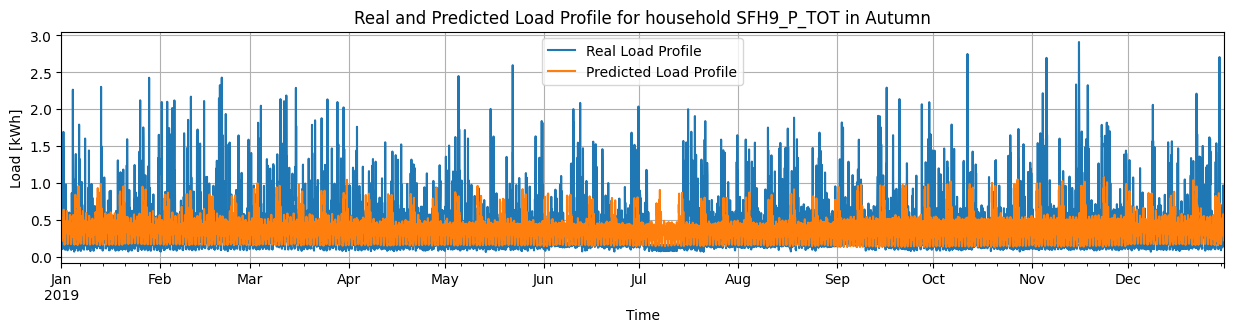

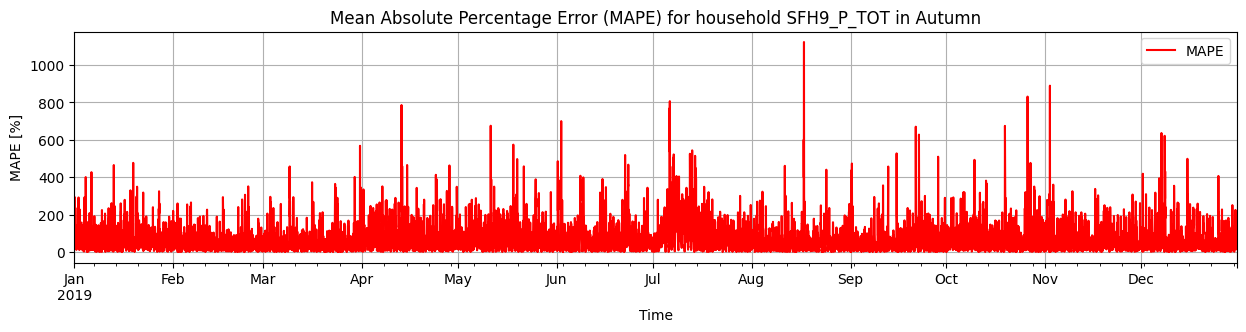

In [121]:
"""
variables: 
- customer_household_data_prediction["Load_prediction"]: Predicted load profile for the customer household
- normalized_data[random_household]: Real load profile for the customer household
"""

# Compare real load profile with the predicted load profile on an hourly basis. Accurate means error < xxx% #TODO: Define the error.
# Calculate the mean absolute percentage error (MAPE) for the predicted load profile
customer_household_data_prediction['MAPE'] = (abs(customer_household_data_prediction['Load_prediction'] - normalized_data[random_household]) / normalized_data[random_household]) * 100
mape = customer_household_data_prediction['MAPE'].mean()
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

# Plot the real load profile and the predicted load profile for the customer household
fig, ax = plt.subplots(figsize=(15, 3))
normalized_data[random_household].plot(ax=ax, label='Real Load Profile')
customer_household_data_prediction['Load_prediction'].plot(ax=ax, label='Predicted Load Profile')
plt.title(f'Real and Predicted Load Profile for household {random_household} in {season_customer_data}')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.legend()
plt.show()




# Plot the MAPE for the predicted load profile
fig, ax = plt.subplots(figsize=(15, 3))
customer_household_data_prediction['MAPE'].plot(ax=ax, label='MAPE', color='red')
plt.title(f'Mean Absolute Percentage Error (MAPE) for household {random_household} in {season_customer_data}')
plt.xlabel('Time')
plt.ylabel('MAPE [%]')
plt.grid(True)
plt.legend()
plt.show()



#### N-MAE

The N-MAE is calculated as the mean of the absolute errors divided by the range (max - min) of the observed data.

Normalized Mean Absolute Error (N-MAE): 0.0705


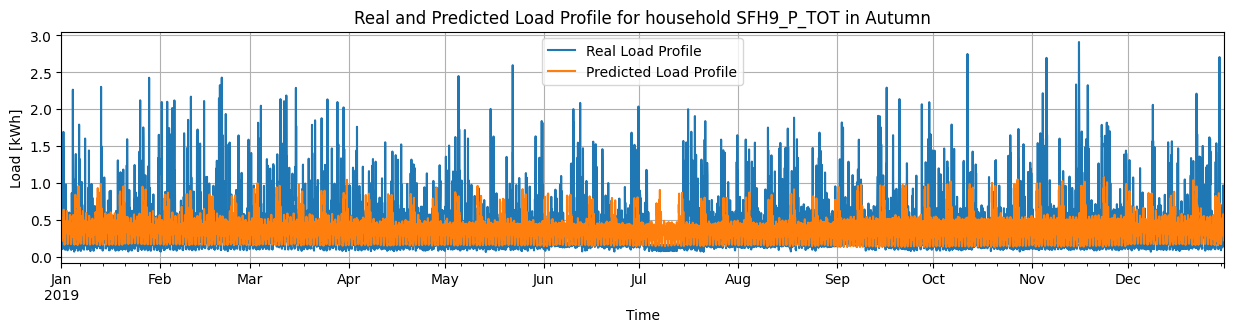

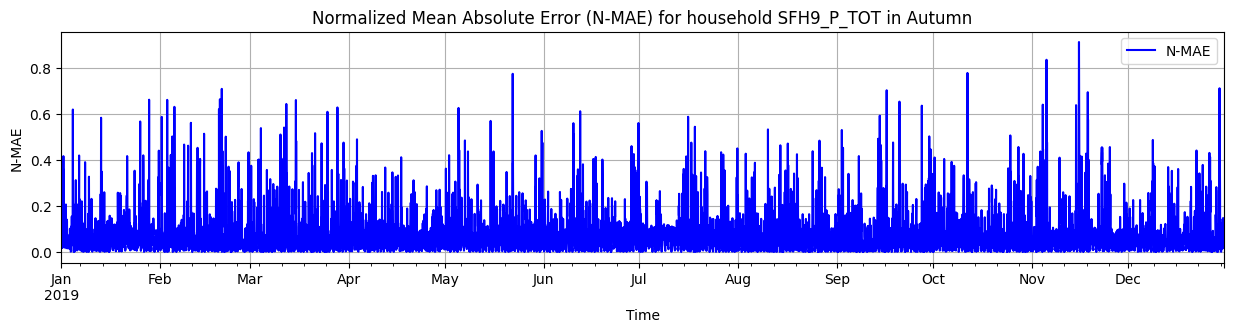

In [122]:
# normalization factor for the real load profile
normalization_factor = normalized_data[random_household].max() - normalized_data[random_household].min()

# normalized mean absolute error (N-MAE) for the predicted load profile
customer_household_data_prediction['N-MAE'] = abs(
    customer_household_data_prediction['Load_prediction'] - normalized_data[random_household]
) / normalization_factor

nmae = customer_household_data_prediction['N-MAE'].mean()
print(f"Normalized Mean Absolute Error (N-MAE): {nmae:.4f}")

# Plot the real load profile and the predicted load profile for the customer household
fig, ax = plt.subplots(figsize=(15, 3))
normalized_data[random_household].plot(ax=ax, label='Real Load Profile')
customer_household_data_prediction['Load_prediction'].plot(ax=ax, label='Predicted Load Profile')
plt.title(f'Real and Predicted Load Profile for household {random_household} in {season_customer_data}')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.legend()
plt.show()

# Plot the N-MAE for the predicted load profile
fig, ax = plt.subplots(figsize=(15, 3))
customer_household_data_prediction['N-MAE'].plot(ax=ax, label='N-MAE', color='blue')
plt.title(f'Normalized Mean Absolute Error (N-MAE) for household {random_household} in {season_customer_data}')
plt.xlabel('Time')
plt.ylabel('N-MAE')
plt.grid(True)
plt.legend()
plt.show()

### Dynamic Prices integration

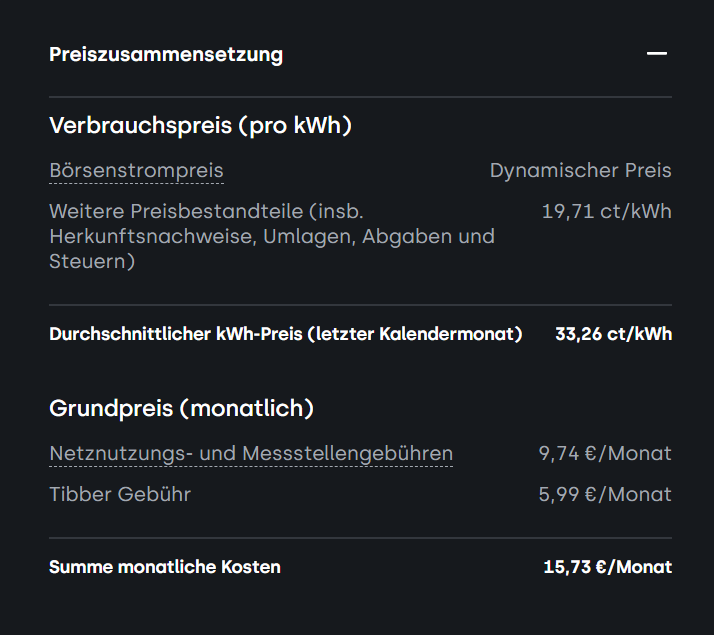
https://tibber.com/de/stromtarif/dynamischer-stromtarif?modal=preisrechner

In [123]:
# Define the missing variables
consumption_dependent_fixed_costs = 19.71  # ct per KwH 2024 value Tibber - Example value, replace with actual value
Consumption_independent_base_price = 15.73  # €/Monat - 2024 value Tibber - Example value, replace with actual value

# Calculate dynamic price in 2019
dynamic_price_per_kwh_2019 = spot_prices_2019['Price ct/KWH'] + consumption_dependent_fixed_costs
dynamic_price_permonth = Consumption_independent_base_price

# Calculate fixed price for the year 2019
fixed_price_per_kwh = electricity_prices_df.loc[electricity_prices_df['Year'] == 2019, 'Summe'].values[0]
print(fixed_price_per_kwh)

30.46


In [124]:
#Compare costs for the customer household
    #Calculate the costs for the customer household based on the dynamic price

customer_household_data_prediction['Price per H'] = customer_household_data_prediction['Load_prediction'] * dynamic_price_per_kwh.values
dynamic_pricing_costs_per_year = customer_household_data_prediction['Price per H'].sum()/100 + dynamic_price_permonth*12 #in €
print(f"Costs for the customer household based on the dynamic price: {dynamic_pricing_costs_per_year:.2f} €")
#print(customer_household_data_prediction['Load_prediction'].sum())
    
#Calculate the costs for the customer household based on the fixed price
fixed_pricing_costs_per_year = (customer_household_data_prediction['Load_prediction'] * fixed_price_per_kwh).sum()/100
print(f"Costs for the customer household based on the fixed price: {fixed_pricing_costs_per_year:.2f} €")

print("------Result------")
if dynamic_pricing_costs_per_year < fixed_pricing_costs_per_year:
    print("Dynamic pricing is cheaper than fixed pricing.")
else:
    print("Fixed pricing is cheaper than dynamic pricing.")

Costs for the customer household based on the dynamic price: 896.06 €
Costs for the customer household based on the fixed price: 913.80 €
------Result------
Dynamic pricing is cheaper than fixed pricing.


#### Real data comparison   

In [127]:
customer_household_real_data = normalized_data_test[random_household]

customer_household_real_data['Dynamic Price per H'] = normalized_data_test[random_household]*dynamic_price_per_kwh.values # in ct
real_dynamic_costs_per_year = customer_household_real_data['Dynamic Price per H'].sum()/100 + dynamic_price_permonth*12 #in €
print(f"Real Costs for the customer household based on the dynamic price: {real_dynamic_costs_per_year:.2f} €")

print(f"Real Costs for the customer household based on the fixed price: {customer_household_real_data.sum()*fixed_price_per_kwh/100:.2f} €")
print("------Result------")
if real_dynamic_costs_per_year < fixed_pricing_costs_per_year:
    print("Dynamic pricing is cheaper than fixed pricing.")
else:
    print("Fixed pricing is cheaper than dynamic pricing.")

print("------Difference to predicted values------")
# Difference between predicted and real costs for dynamic pricing
dynamic_cost_difference = real_dynamic_costs_per_year - dynamic_pricing_costs_per_year
dynamic_cost_difference_percent = ((real_dynamic_costs_per_year - dynamic_pricing_costs_per_year) / dynamic_pricing_costs_per_year) * 100
print(f"Difference between real and predicted dynamic pricing costs: {dynamic_cost_difference:.2f} €")
print(f"Percentage difference between real and predicted dynamic pricing costs: {dynamic_cost_difference_percent:.2f}%")


# Difference between predicted and real costs for fixed pricing
fixed_cost_difference = (normalized_data[random_household].sum() * fixed_price_per_kwh / 100) - fixed_pricing_costs_per_year
print(f"Difference between real and predicted fixed pricing costs: {fixed_cost_difference:.2f} €")
fixed_cost_difference_percent = (((normalized_data[random_household].sum() * fixed_price_per_kwh / 100) - fixed_pricing_costs_per_year) / fixed_pricing_costs_per_year) * 100
print(f"Percentage difference between real and predicted fixed pricing costs: {fixed_cost_difference_percent:.2f}%")

ValueError: operands could not be broadcast together with shapes (8760,) (8736,) 

# EXTRA


## Model
    def calculate_customer_load_profile(df_database_load_profiles, df_customer_profile_two_weeks, customer_anual_consumption):
        """
        Calculate the load profile of a customer based on the load profiles of similar households.

        Parameters:
        - df_database_load_profiles: DataFrame, the DataFrame containing the load profiles of similar households on an hourly basis.
        - df_customer_profile_two_weeks: DataFrame, the DataFrame containing the load profile of the customer for two weeks on an hourly basis.
        - customer_anual_consumption: float, the annual consumption of the customer.

        Returns:
        - DataFrame containing the hourly load profile of the customer for the whole year.
        """
        #TODO
        
        #Regression over df_database_load_profiles to find seasonal and daily patterns in load profiles. Output: load profiel for the whole year based on database


        #Regression over df_customer_profile_two_weeks to predict the load profile for the whole year. Output: load profile for the whole year based on customer data (two weeks)


        #Compare those two load profiles


        #Apply the regression model to the df_customer_profile_two_weeks to predict the load profile for the whole year


        return df_customer_profile
        



## Testing
    def comparing_real_profile_with_predicted_profile(df_real_profile, df_predicted_profile, df_dynamic_price):
        """
        Compare the real load profile with the predicted load profile and calculate the costs for the customer.

        Parameters:
        - df_real_profile: DataFrame, the DataFrame containing the real load profile of the customer on an hourly basis.
        - df_predicted_profile: DataFrame, the DataFrame containing the predicted load profile of the customer on an hourly basis.
        - df_dynamic_price: DataFrame, the DataFrame containing the dynamic price of electricity on an hourly basis.

        Returns:
        - float, the costs for the customer based on the dynamic price of electricity.
        - bool, True if the predicted load profile is accurate, False otherwise.
        """
        #TODO: Write the code

        #Compare the real load profile with the predicted load profile on an hourly basis. True, if the predicted load profile is accurate, False otherwise.
        #Accurate means error < xxx% #TODO: Define the error.

        #Calculate the costs for the customer based on the dynamic price of electricity. The costs are the sum of the product of the predicted load profile and the dynamic price of electricity on an hourly basis.
        


        return costs












def main():
    start_date = '2019-01-01'
    end_date = '2019-12-31'

    #Local Electricity Consumption Data
    hh_path = r"wattWise\local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
    keyword = 'SFH'
    sfh_columns_df = load_and_filter_dataframe(hh_path, keyword, start_date, end_date)
    available_household_loads = sfh_columns_df
    print("Those are available household loads:", available_household_loads)

    #Plot Test Household
    #plot_load_profile(available_household_loads, 'SFH3_P_TOT')

if __name__ == "__main__":
    main()


